# Practical 2 — Simple Linear Regression

**Aim:** Predict a continuous target from **one** input feature with the line ŷ = β₀ + β₁·x, and evaluate it with a
train/test split and k-fold cross-validation using **MSE** and **R²**.

**Dataset:** Diabetes dataset (442 patients, UCI/Efron et al., bundled with scikit-learn). Feature: `bmi`
(body-mass index, standardised); target: a quantitative measure of disease progression one year after baseline.

**Idea:** Ordinary Least Squares (OLS) picks the line that minimises the sum of squared residuals Σ(yᵢ − ŷᵢ)².
For one feature the solution has a closed form:
β₁ = Cov(x, y) / Var(x),  β₀ = ȳ − β₁·x̄.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

pd.set_option("display.precision", 4)

## Evaluation helpers (shared by all regression practicals)
* **MSE** = mean((y - ŷ)²) – average squared error (lower is better)
* **R²** = 1 - SS_res / SS_tot – fraction of the variance of *y* explained by the model (1 is perfect, 0 = no better than predicting the mean)
* `kfold_regression` – manual **k-fold cross-validation**; each fold is held out once as the test set.

In [2]:
from sklearn.base import clone
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import KFold


def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return pd.Series({"MSE": mse, "RMSE": np.sqrt(mse), "R2": r2_score(y_true, y_pred)})


def kfold_regression(model, X, y, k=5, seed=42, verbose=True):
    """K-fold CV. Returns (per-fold table, mean/std summary)."""
    X, y = np.asarray(X), np.asarray(y)
    kf = KFold(n_splits=k, shuffle=True, random_state=seed)
    rows = []
    for fold, (tr, te) in enumerate(kf.split(X), start=1):
        m = clone(model).fit(X[tr], y[tr])                 # fresh, untrained copy each fold
        r = regression_metrics(y[te], m.predict(X[te]))
        r.name = f"Fold {fold}"
        rows.append(r)
        if verbose:
            print(f"Fold {fold}: train={len(tr)}, test={len(te)}, MSE={r['MSE']:.2f}, R2={r['R2']:.4f}")
    folds = pd.DataFrame(rows)
    return folds, pd.DataFrame({"mean": folds.mean(), "std": folds.std()})

## Step 1 — Load and explore the data

Shape: (442, 11) | missing values: 0


,bmi,target
count,4.4200e+02,442.0000
mean,-2.2456e-16,152.1335
std,4.7619e-02,77.0930
min,-9.0275e-02,25.0000
25%,-3.4229e-02,87.0000
50%,-7.2838e-03,140.5000
75%,3.1248e-02,211.5000
max,1.7056e-01,346.0000


Correlation between bmi and target: 0.5865


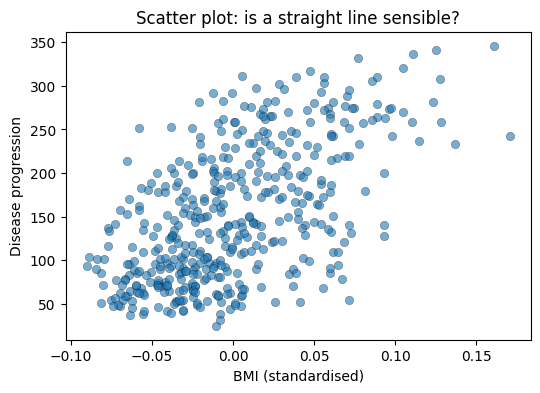

In [3]:
data = load_diabetes(as_frame=True)
df = data.frame
print("Shape:", df.shape, "| missing values:", int(df.isna().sum().sum()))
display(df[["bmi", "target"]].describe())
print("Correlation between bmi and target: %.4f" % df["bmi"].corr(df["target"]))

plt.figure(figsize=(6, 4))
plt.scatter(df["bmi"], df["target"], alpha=0.6, edgecolor="k", linewidth=0.3)
plt.xlabel("BMI (standardised)"); plt.ylabel("Disease progression"); plt.title("Scatter plot: is a straight line sensible?")
plt.show()

## Step 2 — Train / test split
80 % of the rows are used to *learn* the line, 20 % are kept unseen to check how well it generalises.

In [4]:
X = df[["bmi"]].values            # 2-D array (n_samples, 1) – sklearn expects a feature matrix
y = df["target"].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (353, 1) Test: (89, 1)


## Step 3 — What does `LinearRegression.fit()` do? (manual calculation)
1. Compute the means x̄ and ȳ of the training data.
2. Compute the numerator Σ(xᵢ − x̄)(yᵢ − ȳ) (covariance part) and denominator Σ(xᵢ − x̄)² (variance part).
3. Slope β₁ = numerator / denominator.
4. Intercept β₀ = ȳ − β₁·x̄ (forces the line through the point of means).

In [5]:
x = X_train.ravel()
x_bar, y_bar = x.mean(), y_train.mean()
num = np.sum((x - x_bar) * (y_train - y_bar))
den = np.sum((x - x_bar) ** 2)
beta1 = num / den
beta0 = y_bar - beta1 * x_bar

print(f"Step 3.1  x̄ = {x_bar:.6f}, ȳ = {y_bar:.4f}")
print(f"Step 3.2  Σ(x-x̄)(y-ȳ) = {num:.4f},  Σ(x-x̄)² = {den:.4f}")
print(f"Step 3.3  slope  β1 = {num:.4f} / {den:.4f} = {beta1:.4f}")
print(f"Step 3.4  intercept β0 = {y_bar:.4f} - {beta1:.4f} × {x_bar:.6f} = {beta0:.4f}")

Step 3.1  x̄ = 0.001736, ȳ = 153.7365
Step 3.2  Σ(x-x̄)(y-ȳ) = 785.5841,  Σ(x-x̄)² = 0.7867
Step 3.3  slope  β1 = 785.5841 / 0.7867 = 998.5777
Step 3.4  intercept β0 = 153.7365 - 998.5777 × 0.001736 = 152.0034


## Step 4 — Fit with scikit-learn and compare

In [6]:
model = LinearRegression().fit(X_train, y_train)
print(f"sklearn : intercept = {model.intercept_:.4f}, slope = {model.coef_[0]:.4f}")
print(f"manual  : intercept = {beta0:.4f}, slope = {beta1:.4f}")
print("Identical:", np.allclose([model.intercept_, model.coef_[0]], [beta0, beta1]))
print(f"\nFitted equation:  disease_progression = {model.intercept_:.2f} + {model.coef_[0]:.2f} × bmi")

sklearn : intercept = 152.0034, slope = 998.5777
manual  : intercept = 152.0034, slope = 998.5777
Identical: True

Fitted equation:  disease_progression = 152.00 + 998.58 × bmi


## Step 5 — Predictions and metrics step by step
`predict(X)` simply evaluates β₀ + β₁·x for every row. Then:
* residual eᵢ = yᵢ − ŷᵢ
* MSE = mean(eᵢ²)
* R² = 1 − SS_res / SS_tot, where SS_tot = Σ(yᵢ − ȳ)² is the error of the "always predict the mean" baseline.

In [7]:
y_pred = model.predict(X_test)
residuals = y_test - y_pred
ss_res = np.sum(residuals ** 2)
ss_tot = np.sum((y_test - y_test.mean()) ** 2)

print("First 5 predictions :", y_pred[:5].round(2))
print("First 5 actual      :", y_test[:5])
print("First 5 residuals   :", residuals[:5].round(2))
print(f"\nSS_res = {ss_res:.2f}, SS_tot = {ss_tot:.2f}")
print(f"Manual  MSE = {ss_res / len(y_test):.2f},  R² = {1 - ss_res / ss_tot:.4f}")

train_m = regression_metrics(y_train, model.predict(X_train))
test_m = regression_metrics(y_test, y_pred)
display(pd.DataFrame({"Train": train_m, "Test": test_m}))

First 5 predictions : [145.81 188.86 147.96 203.93 131.81]
First 5 actual      : [219.  70. 202. 230. 111.]
First 5 residuals   : [  73.19 -118.86   54.04   26.07  -20.81]

SS_res = 361502.51, SS_tot = 471535.51
Manual  MSE = 4061.83,  R² = 0.2334


,Train,Test
MSE,3854.1127,4061.8259
RMSE,62.0815,63.7325
R2,0.3657,0.2334


## Step 6 — Visual diagnostics

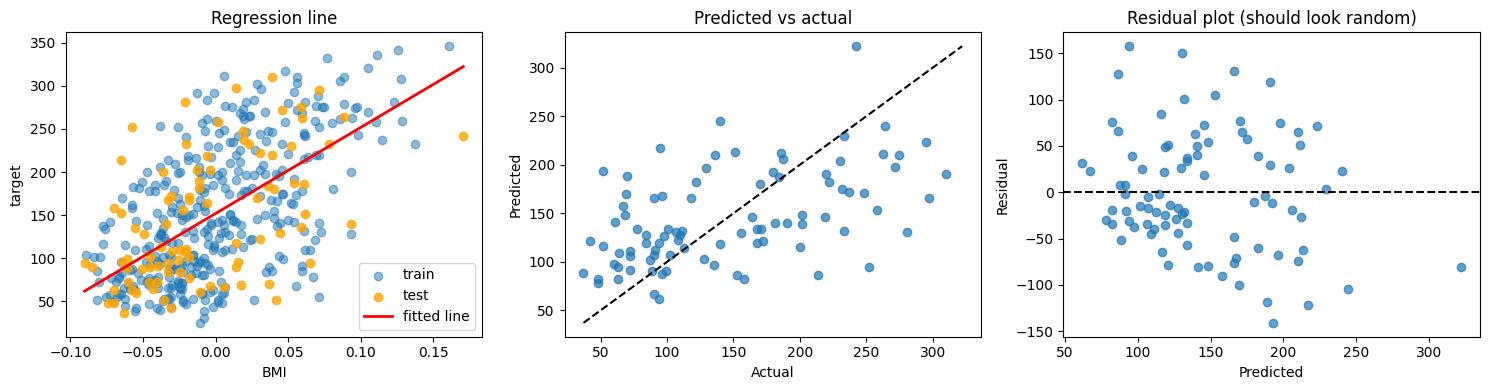

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
grid = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
ax[0].scatter(X_train, y_train, alpha=0.5, label="train")
ax[0].scatter(X_test, y_test, alpha=0.8, c="orange", label="test")
ax[0].plot(grid, model.predict(grid), "r", lw=2, label="fitted line")
ax[0].set(xlabel="BMI", ylabel="target", title="Regression line"); ax[0].legend()

ax[1].scatter(y_test, y_pred, alpha=0.7)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
ax[1].plot(lims, lims, "k--"); ax[1].set(xlabel="Actual", ylabel="Predicted", title="Predicted vs actual")

ax[2].scatter(y_pred, residuals, alpha=0.7); ax[2].axhline(0, color="k", ls="--")
ax[2].set(xlabel="Predicted", ylabel="Residual", title="Residual plot (should look random)")
plt.tight_layout(); plt.show()

## Step 7 — k-fold cross-validation (k = 5)
The data is cut into 5 folds; the model is trained 5 times, each time testing on a different fold.

In [9]:
folds, summary = kfold_regression(LinearRegression(), X, y, k=5)
print()
display(folds.round(4))
display(summary.round(4))

Fold 1: train=353, test=89, MSE=4061.83, R2=0.2334
Fold 2: train=353, test=89, MSE=4098.36, R2=0.3431
Fold 3: train=354, test=88, MSE=3975.34, R2=0.2696
Fold 4: train=354, test=88, MSE=3645.38, R2=0.4584
Fold 5: train=354, test=88, MSE=3915.03, R2=0.2993



,MSE,RMSE,R2
Fold 1,4061.8259,63.7325,0.2334
Fold 2,4098.3564,64.0184,0.3431
Fold 3,3975.3396,63.0503,0.2696
Fold 4,3645.3778,60.3770,0.4584
Fold 5,3915.0300,62.5702,0.2993


,mean,std
MSE,3939.1859,179.2970
RMSE,62.7497,1.4429
R2,0.3207,0.0868


## Step 8 — Summary

In [10]:
display(pd.DataFrame({"Train": train_m, "Hold-out test": test_m, "5-fold CV mean": summary["mean"]}).round(4))

,Train,Hold-out test,5-fold CV mean
MSE,3854.1127,4061.8259,3939.1859
RMSE,62.0815,63.7325,62.7497
R2,0.3657,0.2334,0.3207


### Conclusion
* BMI alone explains only part of the variance in disease progression (R² well below 1) – a single feature is not enough; see Practical 3 for the multi-feature model.
* Train and test scores are close, so the model is not over-fitted (a straight line is too simple to over-fit).
* The residual plot shows spread that is fairly constant, so the linear assumption is reasonable, but a lot of unexplained noise remains.